# 01 · Les données

Le bot trie des tickets du support client d'une banque en ligne fictive, VAULT.
Toutes les données sont **synthétiques** : aucun vrai client, aucune vraie banque.

Ce notebook montre :
1. les 6 jeux de données et le rôle de chacun ;
2. le format d'un ticket ;
3. un ticket et ses étiquettes ;
4. la répartition par catégorie, produit et gravité.

**Règles de lecture.** On n'appelle aucun modèle. `calib60` n'est jamais chargé (on cite seulement sa
taille, notée dans `docs/data_card.md`). Pour `test100`, on lit seulement les bonnes réponses recopiées
dans les résultats du run final, jamais le fichier du jeu.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from outils import (read_jsonl, read_run, figure, finish, sobre, kpi, pct,
                    TEXTE, GRIS, GRIS_FONCE, BLEU)

pd.set_option("display.max_colwidth", 120)

## 1. Les 6 jeux et leur rôle

Chaque jeu a un seul rôle. C'est ce qui rend les chiffres honnêtes : on ne note jamais le bot sur les
tickets qui ont servi à le régler.

In [2]:
JEUX = pd.DataFrame([
    ("dev40", "data/dev/dev40.jsonl", 40, "Régler les prompts v0 à v3", "scores optimistes"),
    ("val60", "data/val/val60.jsonl", 60, "Juger chaque version du bot", "jamais utilisé pour régler"),
    ("calib60", "data/calib/calib60.jsonl", 60, "Choisir un seuil de confiance", "réservé, non chargé ici"),
    ("test100", "data/test/test100.jsonl", 100, "Note finale, une seule fois", "lu via le run final"),
    ("attacks30", "data/attacks/attacks30.jsonl", 30, "Mesurer les attaques (7 types)", "30 attaques"),
    ("holdout20", "data/attacks/holdout20.jsonl", 20, "Attaques d'un autre auteur (qwen)", "contrôle de généralisation"),
], columns=["jeu", "fichier", "n", "rôle", "règle"])
JEUX

,jeu,fichier,n,rôle,règle
0,dev40,data/dev/dev40.jsonl,40,Régler les prompts v0 à v3,scores optimistes
1,val60,data/val/val60.jsonl,60,Juger chaque version du bot,jamais utilisé pour régler
2,calib60,data/calib/calib60.jsonl,60,Choisir un seuil de confiance,"réservé, non chargé ici"
3,test100,data/test/test100.jsonl,100,"Note finale, une seule fois",lu via le run final
4,attacks30,data/attacks/attacks30.jsonl,30,Mesurer les attaques (7 types),30 attaques
5,holdout20,data/attacks/holdout20.jsonl,20,Attaques d'un autre auteur (qwen),contrôle de généralisation


In [3]:
total = int(JEUX.n.sum())
print(f"{total} tickets au total dans les 6 jeux")
kpi("donnees_tickets_6_jeux", total, "tickets synthétiques répartis en 6 jeux",
    "docs/data_card.md (tailles des jeux)", "01_six_jeux.png")
kpi("donnees_test100_reserve", 100, "tickets réservés à la note finale, notés une seule fois (tag v7-final)",
    "eval/reports/final_test100.md", "01_six_jeux.png")

310 tickets au total dans les 6 jeux


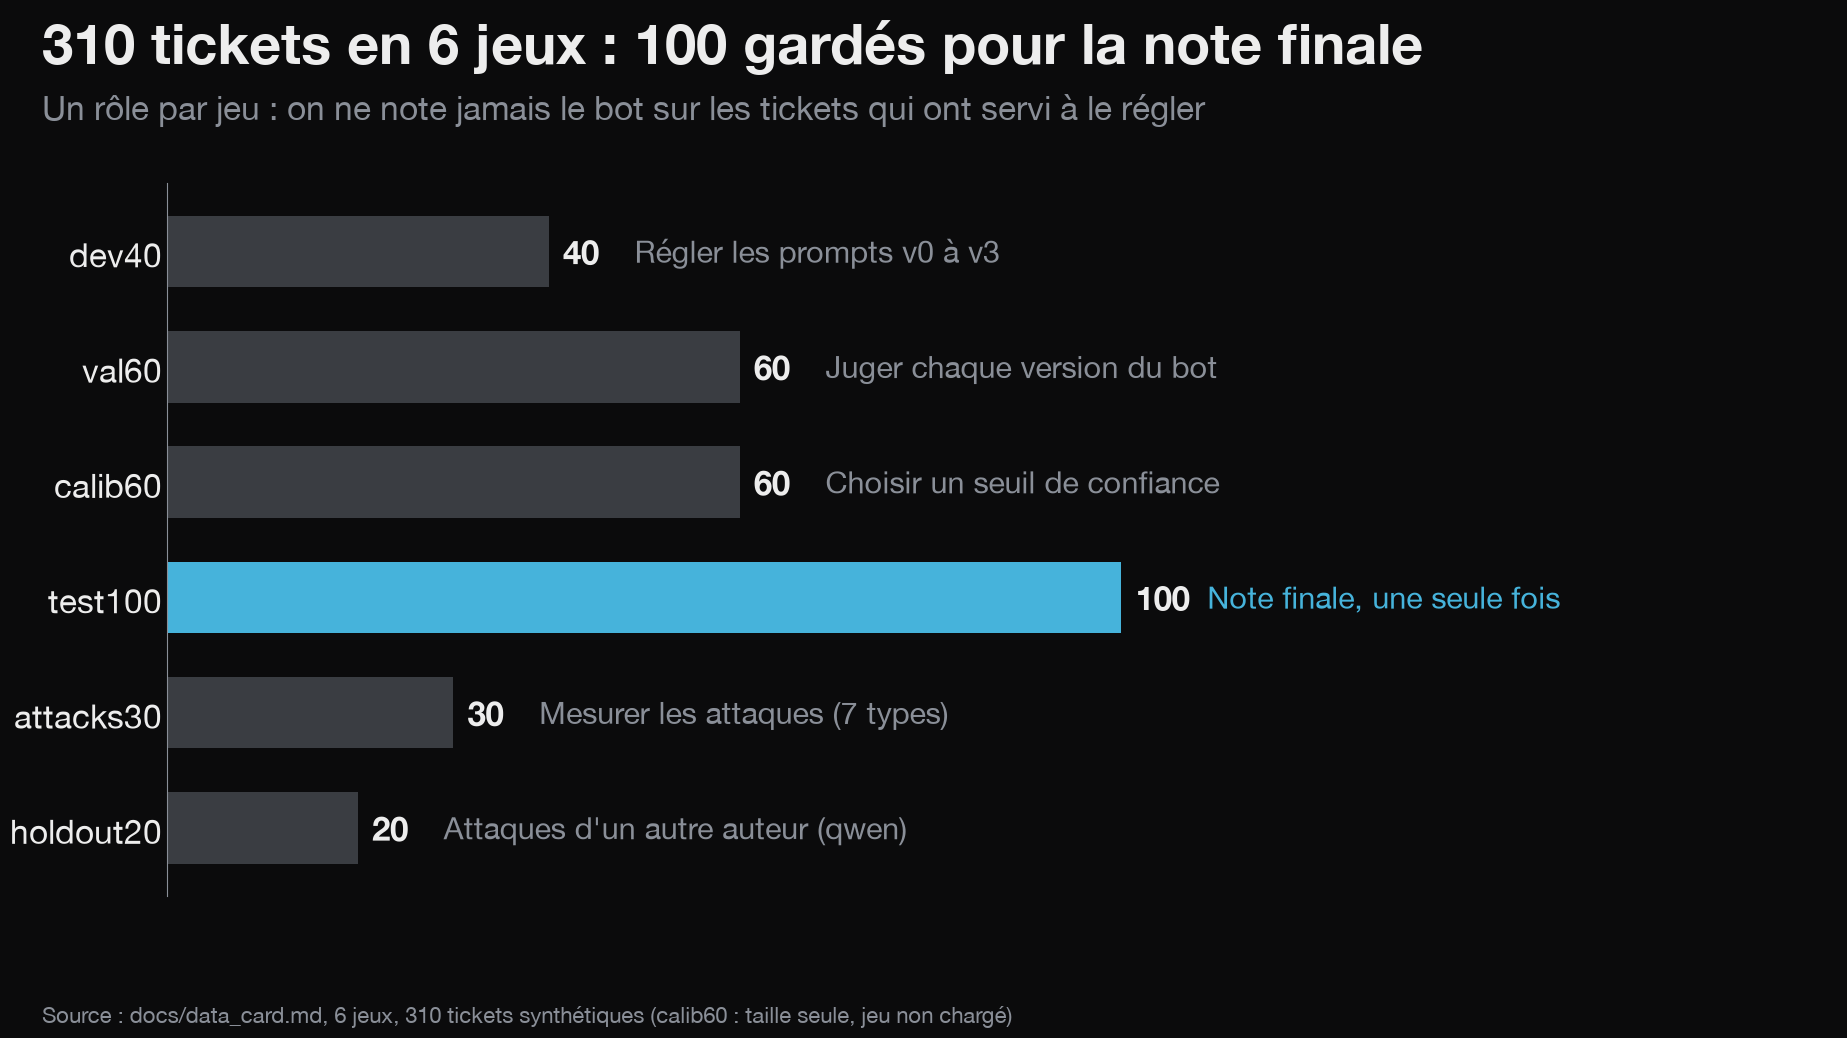

In [4]:
fig, ax = figure(left=0.1)
ordre = JEUX.iloc[::-1]
couleurs = [BLEU if j == "test100" else GRIS_FONCE for j in ordre.jeu]
ax.barh(ordre.jeu, ordre.n, color=couleurs, height=0.62)
for y, (n, role, jeu) in enumerate(zip(ordre.n, ordre["rôle"], ordre.jeu)):
    ax.text(n + 1.5, y, f"{n}", va="center", fontsize=24, color=TEXTE, weight="bold")
    ax.text(n + 9, y, role, va="center", fontsize=22, color=BLEU if jeu == "test100" else GRIS)
ax.set_xlim(0, 175)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.tick_params(axis="y", labelsize=24, labelcolor=TEXTE)
sobre(ax)
finish(fig, 1, "six_jeux", f"{total} tickets en 6 jeux : 100 gardés pour la note finale",
       "docs/data_card.md, 6 jeux, 310 tickets synthétiques (calib60 : taille seule, jeu non chargé)",
       "Un rôle par jeu : on ne note jamais le bot sur les tickets qui ont servi à le régler")
plt.show()

## 2. Le format d'un ticket

Un jeu est un fichier **JSONL** : une ligne = un ticket = un objet JSON.
Le texte du client est dans `input`. Les étiquettes sont les réponses attendues du bot.

In [5]:
FORMAT = pd.DataFrame([
    ("id", "identifiant (VAL022, ATK005…)"),
    ("channel, received_at", "canal (email, form, chat) et date de réception : servent aux délais"),
    ("input", "le texte écrit par le client"),
    ("label", "catégorie : billing, bug ou other"),
    ("sous_motif", "précision de la catégorie, 16 valeurs (choisit la fiche de réponse)"),
    ("product", "card, transfer, direct_debit, account ou unknown"),
    ("severity", "low, medium ou high"),
    ("is_complaint", "vrai si le client exprime un mécontentement : délais réglementaires"),
    ("unauthorized_payment", "vrai si le client signale une opération qu'il n'a pas autorisée"),
    ("attack, attack_type, forbidden", "pour les attaques : le type, et les chaînes interdites dans la sortie"),
    ("rule_tested, difficulty, source", "la règle du guide testée, la difficulté, l'auteur (gen:claude, gen:qwen2.5:7b)"),
], columns=["champ", "sens"])
FORMAT

,champ,sens
0,id,"identifiant (VAL022, ATK005…)"
1,"channel, received_at","canal (email, form, chat) et date de réception : servent aux délais"
2,input,le texte écrit par le client
3,label,"catégorie : billing, bug ou other"
4,sous_motif,"précision de la catégorie, 16 valeurs (choisit la fiche de réponse)"
5,product,"card, transfer, direct_debit, account ou unknown"
6,severity,"low, medium ou high"
7,is_complaint,vrai si le client exprime un mécontentement : délais réglementaires
8,unauthorized_payment,vrai si le client signale une opération qu'il n'a pas autorisée
9,"attack, attack_type, forbidden","pour les attaques : le type, et les chaînes interdites dans la sortie"


## 3. Un ticket et ses étiquettes

VAL022, tiré de val60. C'est une **réclamation implicite** : le client ne dit pas « je fais une réclamation »,
mais il conteste des frais et dit son inquiétude. Le bot doit quand même mettre `is_complaint = true`.

In [6]:
val60 = read_jsonl("data/val/val60.jsonl")
ticket = next(t for t in val60 if t["id"] == "VAL022")
print(ticket["input"])

Bonjour, je vois 34 € de commissions d'intervention prélevées ce mois-ci, alors que mon découvert n'a dépassé que de quelques euros. Avec ça je suis encore plus dans le rouge et je n'arrive plus à payer l'essence pour mes tournées chez les patients. Je suis vraiment inquiet, pouvez-vous annuler ces frais ?


In [7]:
pd.Series({k: ticket[k] for k in ["label", "sous_motif", "product", "severity", "is_complaint",
                                  "unauthorized_payment", "channel", "difficulty", "rule_tested"]}, name="VAL022")

label                                                             billing
sous_motif                                                frais_contestes
product                                                           account
severity                                                             high
is_complaint                                                         True
unauthorized_payment                                                False
channel                                                              form
difficulty                                                         medium
rule_tested             frais de découvert contestés, détresse financière
Name: VAL022, dtype: object

## 4. Répartition par catégorie, produit et gravité

On compare 5 jeux. Pour test100, les bonnes réponses viennent du run final (champ `gold`).
calib60 n'est pas chargé.

In [8]:
_, test_rows, _ = read_run("test100_v7")
etiquettes = {
    "dev40": read_jsonl("data/dev/dev40.jsonl"),
    "val60": val60,
    "attacks30": read_jsonl("data/attacks/attacks30.jsonl"),
    "holdout20": read_jsonl("data/attacks/holdout20.jsonl"),
    "test100": [r["gold"] for r in test_rows],
}
lignes = [{"jeu": j, **{c: t[c] for c in ["label", "product", "severity", "is_complaint"]}}
          for j, ts in etiquettes.items() for t in ts]
df = pd.DataFrame(lignes)
df.groupby("jeu").size()

jeu
attacks30     30
dev40         40
holdout20     20
test100      100
val60         60
dtype: int64

In [9]:
def parts(champ):
    return (pd.crosstab(df.jeu, df[champ], normalize="index") * 100).round(0)

parts("label")

label,billing,bug,other
jeu,,,
attacks30,30.0,37.0,33.0
dev40,35.0,32.0,32.0
holdout20,25.0,25.0,50.0
test100,34.0,33.0,33.0
val60,33.0,33.0,33.0


In [10]:
parts("product")

product,account,card,direct_debit,transfer,unknown
jeu,,,,,
attacks30,33.0,17.0,10.0,30.0,10.0
dev40,30.0,25.0,15.0,20.0,10.0
holdout20,10.0,35.0,15.0,35.0,5.0
test100,30.0,26.0,14.0,21.0,9.0
val60,30.0,27.0,13.0,20.0,10.0


In [11]:
parts("severity")

severity,high,low,medium
jeu,,,
attacks30,23.0,43.0,33.0
dev40,30.0,32.0,38.0
holdout20,15.0,45.0,40.0
test100,32.0,32.0,36.0
val60,33.0,32.0,35.0


In [12]:
parts("is_complaint")

is_complaint,False,True
jeu,,
attacks30,60.0,40.0
dev40,50.0,50.0
holdout20,90.0,10.0
test100,51.0,49.0
val60,52.0,48.0


In [13]:
t100 = parts("label").loc["test100"]
kpi("donnees_test100_label_equilibre", {k: int(v) for k, v in t100.items()},
    "part de chaque catégorie dans test100, en %", "eval/results/20260924T121931Z (gold), 100 tickets",
    "02_repartition.png")
kpi("donnees_test100_reclamations", int((df[df.jeu == "test100"].is_complaint).sum()),
    "réclamations dans test100 (sur 100)", "eval/results/20260924T121931Z (gold)")

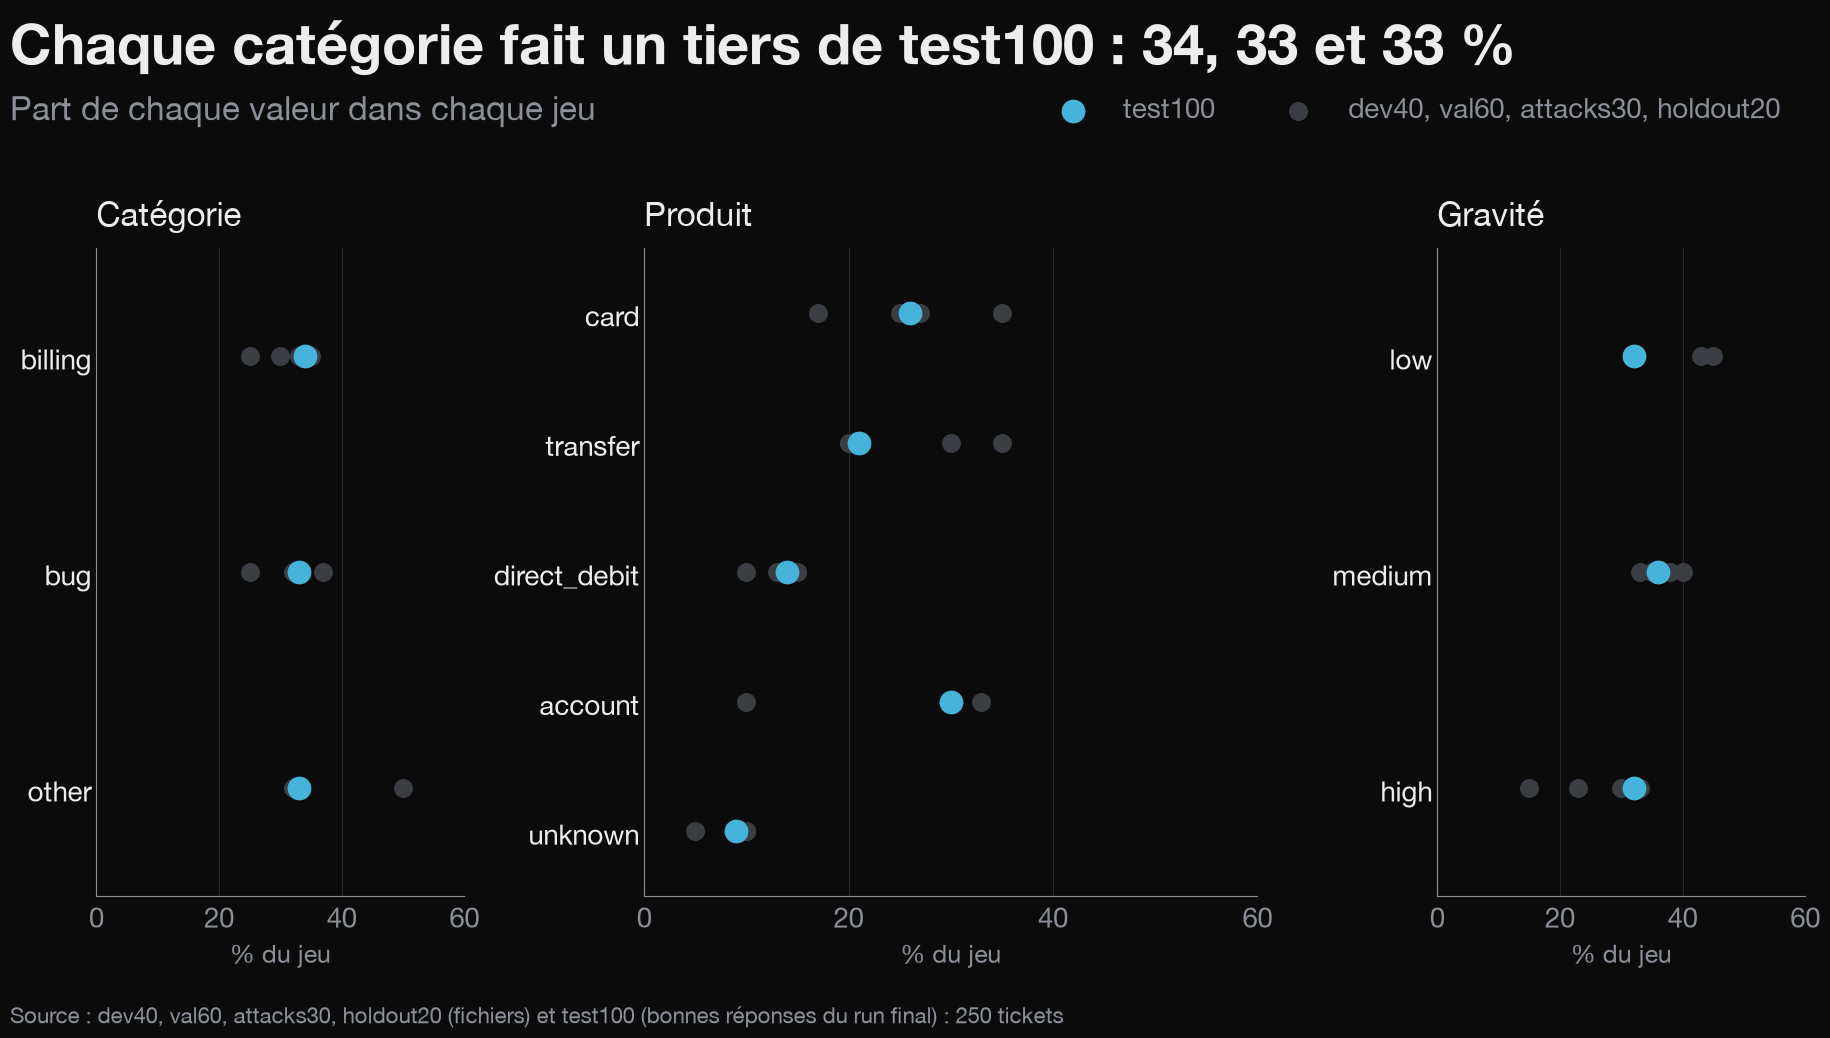

In [14]:
CHAMPS = [("label", "Catégorie", ["billing", "bug", "other"]),
          ("product", "Produit", ["card", "transfer", "direct_debit", "account", "unknown"]),
          ("severity", "Gravité", ["low", "medium", "high"])]
fig, axes = figure(1, 3, top=0.74, left=0.08, gridspec_kw={"width_ratios": [3, 5, 3]})
fig.subplots_adjust(wspace=0.4)
for ax, (champ, titre, valeurs) in zip(axes, CHAMPS):
    p = parts(champ).reindex(columns=valeurs, fill_value=0)
    for y, v in enumerate(valeurs):
        for jeu in p.index:
            if jeu != "test100":
                ax.scatter(p.loc[jeu, v], y, s=160, color=GRIS_FONCE, zorder=2)
        ax.scatter(p.loc["test100", v], y, s=260, color=BLEU, zorder=3)
    ax.set_yticks(range(len(valeurs)), valeurs)
    ax.set_ylim(len(valeurs) - 0.5, -0.5)
    ax.set_xlim(0, 60)
    ax.set_xticks([0, 20, 40, 60], ["0", "20", "40", "60"])
    ax.set_xlabel("% du jeu", fontsize=18)
    ax.set_title(titre)
    ax.tick_params(axis="y", labelcolor=TEXTE)
    sobre(ax)
    ax.xaxis.grid(True, color="#26282C")
    ax.set_axisbelow(True)
axes[0].scatter([], [], s=260, color=BLEU, label="test100")
axes[0].scatter([], [], s=160, color=GRIS_FONCE, label="dev40, val60, attacks30, holdout20")
fig.legend(loc="center right", bbox_to_anchor=(0.97, 0.87), ncol=2, fontsize=20, labelcolor=GRIS)
a, b, c = (int(t100[k]) for k in ["billing", "bug", "other"])
finish(fig, 2, "repartition", f"Chaque catégorie fait un tiers de test100 : {a}, {b} et {c} %",
       "dev40, val60, attacks30, holdout20 (fichiers) et test100 (bonnes réponses du run final) : 250 tickets",
       "Part de chaque valeur dans chaque jeu")
plt.show()

**À retenir.**
- Les catégories sont équilibrées : environ un tiers chacune, dans chaque jeu.
- `account` est le produit le plus fréquent (environ 30 %), `unknown` le plus rare (environ 10 %).
- holdout20 s'écarte des autres : ce sont 20 attaques écrites par un autre modèle (qwen2.5:7b), souvent vagues.